# M03-L06 — Classificação de Imagens com Features Extraídas

**Duração estimada:** 2 horas
**Regime de Ferramentas:** Python nativo + pandas + matplotlib + scikit-learn + NumPy (sem biblioteca nova em relação à M03-L05).

## Instruções iniciais

1. Abra este notebook no Google Colab.
2. Salve imediatamente uma cópia no seu Google Drive (`Arquivo > Salvar uma cópia no Drive`).
3. Execute todas as células **na ordem**, de cima para baixo. Algumas células dependem de variáveis criadas em células anteriores.
4. Este notebook não introduz nenhuma biblioteca nova em relação à M03-L05. Todos os exercícios desta lição são respondidos em texto (célula Markdown), não em código.
5. Ao final, você deve entregar este notebook executado, com todas as células de texto preenchidas e o checklist marcado.


## 1. Retomada condensada da M03-L05

Vamos reexecutar, de forma condensada, o download das três fotos do Iris e a redução de resolução, exatamente como feito na M03-L05. Não vamos reexplorar canais, escala de cinza ou threshold em detalhe — isso já foi feito na lição anterior.


In [23]:
import urllib.request
imagens = {
    "iris_setosa.jpg": "https://upload.wikimedia.org/wikipedia/commons/5/56/Kosaciec_szczecinkowaty_Iris_setosa.jpg",
    "iris_versicolor.jpg": "https://upload.wikimedia.org/wikipedia/commons/4/41/Iris_versicolor_3.jpg",
    "iris_virginica.jpg": "https://upload.wikimedia.org/wikipedia/commons/9/9f/Iris_virginica.jpg",
}

for nome_arquivo, url in imagens.items():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response:
        with open(nome_arquivo, "wb") as f:
            f.write(response.read())

print("Imagens baixadas:", list(imagens.keys()))


Imagens baixadas: ['iris_setosa.jpg', 'iris_versicolor.jpg', 'iris_virginica.jpg']


iris_setosa.jpg shape reduzido: (160, 120, 3)
iris_versicolor.jpg shape reduzido: (186, 248, 3)
iris_virginica.jpg shape reduzido: (244, 300, 3)


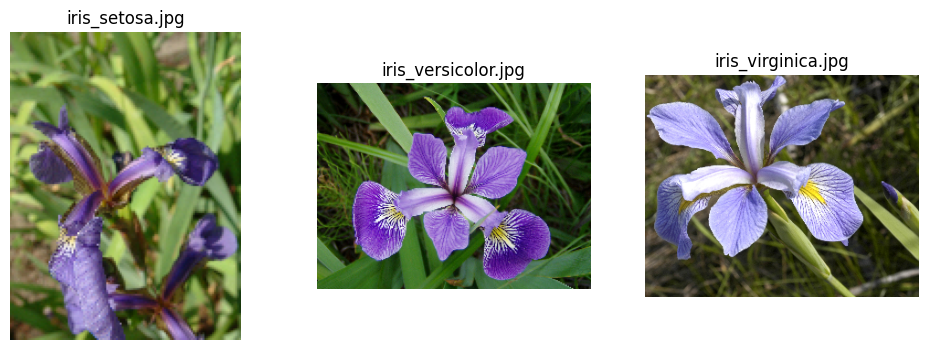

In [24]:
import matplotlib.pyplot as plt

# Carregamento e redução de resolução (fatiamento), como na M03-L05
PASSO = 8  # mesmo fator de redução usado na M03-L05

imagens_originais = {}
for classe, url in imagens.items():
    img = plt.imread(classe)
    img_reduzida = img[::PASSO, ::PASSO]
    imagens_originais[classe] = img_reduzida
    print(classe, "shape reduzido:", img_reduzida.shape)

fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
for eixo, (classe, img) in zip(eixos, imagens_originais.items()):
    eixo.imshow(img)
    eixo.set_title(classe)
    eixo.axis("off")
plt.show()



## 2. Exemplo guiado 1 — Função extratora de features de uma única imagem

A função abaixo recebe um array de imagem (3D) e um limiar de threshold, e devolve um **dicionário de números** — a "tradução" da imagem para o formato que a scikit-learn entende. Ela reaproveita exatamente as operações já vistas na M03-L05 (separação de canais, escala de cinza, threshold), sem introduzir nenhuma biblioteca nova.


In [25]:
def extrair_features_imagem(img_array, limiar_threshold=110):
    """Recebe um array de imagem (altura, largura, canais) e devolve
    um dicionario de features numericas: media e desvio padrao dos
    canais R/G/B, desvio padrao da escala de cinza e proporcao de
    pixels segmentados via threshold."""
    canal_r = img_array[:, :, 0].astype(float)
    canal_g = img_array[:, :, 1].astype(float)
    canal_b = img_array[:, :, 2].astype(float)

    imagem_cinza = img_array.mean(axis=2)
    mascara = imagem_cinza > limiar_threshold

    features = {
        "media_r": canal_r.mean(),
        "media_g": canal_g.mean(),
        "media_b": canal_b.mean(),
        "std_cinza": imagem_cinza.std(),
        "prop_segmentada": mascara.mean(),
    }
    return features


# Aplicando a funcao as tres fotos originais
features_originais = {}
for classe, img in imagens_originais.items():
    features_originais[classe] = extrair_features_imagem(img)

for classe, feats in features_originais.items():
    print(classe, "->", feats)


iris_setosa.jpg -> {'media_r': np.float64(108.63005208333334), 'media_g': np.float64(117.47125), 'media_b': np.float64(80.90890625), 'std_cinza': np.float64(42.478069777618366), 'prop_segmentada': np.float64(0.42953125)}
iris_versicolor.jpg -> {'media_r': np.float64(79.98642906694415), 'media_g': np.float64(87.51500173430455), 'media_b': np.float64(81.10711498439126), 'std_cinza': np.float64(56.585880658421566), 'prop_segmentada': np.float64(0.2958289975719736)}
iris_virginica.jpg -> {'media_r': np.float64(103.23683060109289), 'media_g': np.float64(102.86467213114754), 'media_b': np.float64(96.565956284153), 'std_cinza': np.float64(68.95512090908248), 'prop_segmentada': np.float64(0.35722677595628416)}


### Exercício 1 (texto/Markdown)

Observe os três dicionários de features exibidos acima. Responda abaixo, com suas próprias palavras:

**Qual feature parece diferenciar melhor `setosa` das demais espécies? Justifique com os números observados.**

_Escreva sua resposta aqui:_

> Acredito que as melhores feature para diferenciarmos a `setosa` das demais é a `prop_segmentada` e a `std_cinza_`. Quando analisamos os números, vemos que os valores desta espécie são significativamente diferentes (sendo geralmente mais altos ou mais baixos), assim como os canais de cor também. Quando cemos `versicolor`e `virginica`, essas espécies possuem características de coloração e área de pixels segmentados mais próximas entre si.A setosa apresenta um `std_cinza` e uma `prop_segmentada`de tamanhos como 24.47 e de 0.42 que quando vamos ver nos outros, é mais de 56 e proporção de pixels menores, como 0.29 e 0.35.


## 3. Exemplo guiado 2 — Gerando um dataset tabular de amostras de imagem

Três fotos (uma por classe) não bastam para treinar e testar um classificador. Vamos gerar de 15 a 30 variações controladas de cada foto — pequenos recortes e leves alterações de iluminação — com semente fixa (`np.random.seed(42)`), para que todos os participantes obtenham exatamente o mesmo conjunto de amostras.


In [26]:
import pandas as pd
import numpy as np

np.random.seed(42)  # reprodutibilidade: mesma "moeda" para todos os participantes

N_AMOSTRAS_POR_CLASSE = 20

def gerar_variacao(img_array):
    """Gera uma variacao controlada da imagem: um recorte pequeno
    e um fator de iluminacao levemente diferente."""
    altura, largura, _ = img_array.shape

    # recorte aleatorio de ~80% da imagem
    corte_h = int(altura * 0.8)
    corte_w = int(largura * 0.8)
    ini_h = np.random.randint(0, altura - corte_h + 1)
    ini_w = np.random.randint(0, largura - corte_w + 1)
    recorte = img_array[ini_h:ini_h + corte_h, ini_w:ini_w + corte_w]

    # variacao leve de iluminacao (entre 0.85x e 1.15x)
    fator_luz = np.random.uniform(0.85, 1.15)
    variacao = np.clip(recorte.astype(float) * fator_luz, 0, 255).astype(np.uint8)
    return variacao


linhas_features = []
for classe, img in imagens_originais.items():
    for _ in range(N_AMOSTRAS_POR_CLASSE):
        variacao = gerar_variacao(img)
        feats = extrair_features_imagem(variacao)
        feats["classe"] = classe
        linhas_features.append(feats)

df_features = pd.DataFrame(linhas_features)
df_features.head()


,media_r,media_g,media_b,std_cinza,prop_segmentada,classe
0,113.143229,117.057943,92.568115,47.942336,0.454915,iris_setosa.jpg
1,106.577148,111.656494,82.794515,42.995207,0.403727,iris_setosa.jpg
2,105.721029,110.465495,83.889242,43.533343,0.405355,iris_setosa.jpg
3,93.458903,97.462484,72.029053,37.638442,0.278320,iris_setosa.jpg
4,119.753906,131.701742,90.631999,46.467843,0.515462,iris_setosa.jpg


In [27]:
df_features.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   media_r          60 non-null     float64
 1   media_g          60 non-null     float64
 2   media_b          60 non-null     float64
 3   std_cinza        60 non-null     float64
 4   prop_segmentada  60 non-null     float64
 5   classe           60 non-null     object 
dtypes: float64(5), object(1)
memory usage: 2.9+ KB


In [28]:
df_features["classe"].value_counts()


,count
classe,
iris_setosa.jpg,20
iris_versicolor.jpg,20
iris_virginica.jpg,20


### Exercício 2 (texto/Markdown)

Observe as saídas de `.info()` e `.value_counts()` acima. Responda:

**Quantas amostras existem por classe? A tabela está balanceada? Qual é a coluna-alvo? O que você observa de diferente entre a escala de `prop_segmentada` e a das colunas de média de canal?**

_Escreva sua resposta aqui:_

> Existem 20 amostras por classe, totalizando 60 amostras. A tabela está bem balanceada. A  coluna-alvo seria a coluna `classe` (pensando que seria a categoria que o modelo deve aprender a prever). Sobre a `prop_segmentada`, podemos ver que sempre fica entre 0 e 1, nunca saindo disso, enquanto as outras sempre tem uma taxa de variação muito maior.


## 4. Exemplo guiado 3 — Treinamento e avaliação dos classificadores clássicos

Agora reaplicamos exatamente o mesmo pipeline de classificação já usado na M03-L03/M03-L04 — a única novidade é que as colunas de `X` vieram de uma imagem, não de uma medida física da flor.


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

colunas_features = ["media_r", "media_g", "media_b", "std_cinza", "prop_segmentada"]
X = df_features[colunas_features]
y = df_features["classe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
    "KNeighborsClassifier": KNeighborsClassifier(),
}

modelos_treinados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    modelos_treinados[nome] = modelo
    y_pred = modelo.predict(X_test)
    print(f"--- {nome} ---")
    print(classification_report(y_test, y_pred))
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, y_pred, labels=modelo.classes_))
    print()


--- LogisticRegression ---
                     precision    recall  f1-score   support

    iris_setosa.jpg       1.00      1.00      1.00         6
iris_versicolor.jpg       1.00      1.00      1.00         6
 iris_virginica.jpg       1.00      1.00      1.00         6

           accuracy                           1.00        18
          macro avg       1.00      1.00      1.00        18
       weighted avg       1.00      1.00      1.00        18

Matriz de confusão:
[[6 0 0]
 [0 6 0]
 [0 0 6]]

--- DecisionTreeClassifier ---
                     precision    recall  f1-score   support

    iris_setosa.jpg       1.00      1.00      1.00         6
iris_versicolor.jpg       0.71      0.83      0.77         6
 iris_virginica.jpg       0.80      0.67      0.73         6

           accuracy                           0.83        18
          macro avg       0.84      0.83      0.83        18
       weighted avg       0.84      0.83      0.83        18

Matriz de confusão:
[[6 0 0]
 [0 

### Exercício 3 (texto/Markdown)

Compare as métricas dos três modelos acima. Responda:

**Qual modelo teve melhor desempenho? Qual classe apresentou mais confusão? Isso é esperado, considerando o que você já observou sobre o fundo irregular das fotos na M03-L05?**

_Escreva sua resposta aqui:_

> Apenas o modelo de Árvore de Decisão teve um desempenho abaixo do esperado. Contudo, isso já era de se esperar pelo fundo das imagens estarem com ruídos, sombras e outros elementos que iriam dificultar uma segmentação perfeita.


## 5. Exemplo guiado 4 — Teste de estresse por iluminação

Vamos simular uma mudança de iluminação (multiplicando os canais RGB das amostras de teste por um fator diferente) e reavaliar o modelo **já treinado**, sem retreiná-lo. Isso expõe o gargalo das características manuais: o classificador só enxerga o que o engenheiro humano decidiu medir.


In [30]:
def aplicar_mudanca_iluminacao(img_array, fator=1.6):
    """Simula uma mudanca abrupta de iluminacao multiplicando os canais."""
    return np.clip(img_array.astype(float) * fator, 0, 255).astype(np.uint8)


# Regeneramos amostras de teste com a mesma logica, mas aplicando
# a mudanca de iluminacao ANTES da extracao de features
np.random.seed(42)
linhas_teste_estresse = []
for classe, img in imagens_originais.items():
    for _ in range(N_AMOSTRAS_POR_CLASSE):
        variacao = gerar_variacao(img)
        variacao_com_luz = aplicar_mudanca_iluminacao(variacao)
        feats = extrair_features_imagem(variacao_com_luz)
        feats["classe"] = classe
        linhas_teste_estresse.append(feats)

df_estresse = pd.DataFrame(linhas_teste_estresse)
X_estresse = df_estresse[colunas_features]
y_estresse = df_estresse["classe"]

# Usamos o MESMO modelo ja treinado (sem retreinar)
modelo_para_teste = modelos_treinados["LogisticRegression"]
y_pred_estresse = modelo_para_teste.predict(X_estresse)

print("--- Avaliação sob mudança de iluminação (sem retreinar) ---")
print(classification_report(y_estresse, y_pred_estresse))


--- Avaliação sob mudança de iluminação (sem retreinar) ---
                     precision    recall  f1-score   support

    iris_setosa.jpg       1.00      1.00      1.00        20
iris_versicolor.jpg       0.00      0.00      0.00        20
 iris_virginica.jpg       0.50      1.00      0.67        20

           accuracy                           0.67        60
          macro avg       0.50      0.67      0.56        60
       weighted avg       0.50      0.67      0.56        60



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Compare** o `classification_report` acima com o resultado original da `LogisticRegression` no Exemplo guiado 3. A queda de desempenho (se houver) é o "gargalo das features manuais" em ação: a mesma flor, sob outra iluminação, pode deixar de ser reconhecida.


## 6. Exemplo de erro comum

A célula abaixo contém **dois erros propositais**, comuns nesta fusão entre imagem e ML tabular. Execute a célula e observe o resultado — não corrija o código, apenas leia a mensagem de erro/resultado.


In [31]:
# ERRO PROPOSITAL 1: tentar passar a imagem 3D diretamente para .fit()
try:
    modelo_erro = LogisticRegression()
    modelo_erro.fit(imagens_originais["virginica"], ["virginica"])
except ValueError as erro:
    print("Erro 1 (imagem 3D direta):")
    print(erro)

print()

# ERRO PROPOSITAL 2: aplicar a extracao de features so no treino,
# esquecendo o teste (aqui simulado usando a imagem crua como "teste")
try:
    modelo_erro2 = LogisticRegression(max_iter=1000)
    modelo_erro2.fit(X_train, y_train)
    # "esquecemos" de extrair features do array de teste bruto
    predicao_incorreta = modelo_erro2.predict(imagens_originais["setosa"].reshape(1, -1))
except ValueError as erro:
    print("Erro 2 (features não extraídas no teste):")
    print(erro)


KeyError: 'virginica'

### Exercício de correção de erro (texto/Markdown)

Sem reescrever a célula acima, explique por escrito:

**Por que cada um dos dois erros ocorre? O que precisaria mudar no código para corrigir cada um?**

_Escreva sua resposta aqui:_

> Erro 1: O erro ocorreu pois o modelo do scikit-learn espera receber dados em formato tubular (conforme dito no próprio enunciado). Para corrigir isso, precisamos fazer com que o `fit()` receba os dados com as features numéricas já extraídas, não o array da imagem original.
>
> Erro 2: Agora, o segundo erro ocorre pois o modelo foi treinado para entender e definir cinco features distintas e com suas especificidades, mas quando fomos fazer a predição, foi recebido um array com os pixels brutos achatados. A quantidade e o significado das colunas não batem. Para conseguirmos corrigir isso, precisamos aplicar a mesma extração de features na imagem de teste.


## 7. Desafio extra opcional (guiado + textual)

Para participantes com mais experiência: o código abaixo já vem pronto (você não precisa escrever nada). Ele calcula uma nova feature — a razão entre os canais azul e vermelho (`B / (R + 1e-5)`) — inclui essa coluna na tabela de features e retreina o KNN.


In [ ]:
# Exemplo guiado pronto — desafio extra (sem escrita de código do participante)
df_features_extra = df_features.copy()
df_features_extra["razao_b_r"] = df_features_extra["media_b"] / (df_features_extra["media_r"] + 1e-5)

colunas_features_extra = colunas_features + ["razao_b_r"]
X_extra = df_features_extra[colunas_features_extra]
y_extra = df_features_extra["classe"]

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_extra, y_extra, test_size=0.3, stratify=y_extra, random_state=42
)

knn_extra = KNeighborsClassifier()
knn_extra.fit(X_train_e, y_train_e)
y_pred_extra = knn_extra.predict(X_test_e)

print("--- KNN COM a nova feature razao_b_r ---")
print(classification_report(y_test_e, y_pred_extra))

print("--- KNN SEM a nova feature (referência, do Exemplo guiado 3) ---")
knn_referencia = modelos_treinados["KNeighborsClassifier"]
y_pred_referencia = knn_referencia.predict(X_test)
print(classification_report(y_test, y_pred_referencia))


### Resposta do desafio extra (texto/Markdown)

Compare os dois `classification_report` acima (KNN com e sem a nova feature `razao_b_r`).

**A nova feature pareceu ajudar (ou não) a separar as três espécies do Iris? Por quê?**

_Escreva sua resposta aqui:_

> A nova feature `razao_n` não apresentou nada que apresentou melhorias ou auxílio para separar as três espécies do Iris quando vamos verificar as métricas, (que permaneceram as mesmas). Isso nos faz deduzir que, para estes dados em específico, as features originais já bastavam para a segmentação. Essa feature adicionada não trouxe nada de novo para a segmentação.

## 8. Reflexão final (texto/Markdown)

Compare, com suas próprias palavras, a abordagem de features manuais construída nesta lição com o que será visto no Módulo M04 (Aprendizagem Profunda).

**Quais foram os passos manuais que você precisou fazer para transformar imagem em tabela? O que você imagina que uma rede neural faria de diferente?**

_Escreva sua resposta aqui:_

> Quando fomos transformar as imagens manuais em tabelas, tivemos que escolher, calcular utilizando matemática e entendermos e fazermos testes para ver como a tabela estava se comportando. Acredito que se fosse uma uma rede neural, ela faria isso automaticamente depois de programada e treinada. Ela facilmente usaria seu aprendizado para identificar e extrair sozinha as características da imagem.


## 9. Checklist de conclusão

- [x] Abri o notebook no Google Colab e salvei uma cópia no meu Google Drive.
- [x] Executei todas as células de texto e código, na ordem, incluindo a retomada da M03-L05.
- [x] Executei a função extratora de features sobre as três fotos originais e registrei qual feature melhor diferencia `setosa`.
- [x] Executei a geração das amostras sintéticas e a montagem da tabela `df_features`, interpretando `.info()` e `.value_counts()`.
- [x] Executei o treino e a avaliação dos três classificadores clássicos sobre a tabela de features de imagem.
- [x] Interpretei o `classification_report` e a matriz de confusão de cada modelo.
- [x] Executei o teste de estresse por iluminação e registrei minha análise crítica sobre a queda de desempenho.
- [x] Diagnostiquei por escrito os dois erros propositais apresentados.
- [x] Li o exemplo guiado do desafio extra e registrei minha análise sobre a nova feature de razão de canais.
- [x] Preenchi a reflexão final comparando features manuais e Aprendizagem Profunda.
- [x] Finalizei o laboratório da lição M03-L06.


## 10. Orientação de entrega

Mantenha salvo, no seu Google Drive, este notebook com **todas** as células executadas na ordem e **todas** as respostas em texto preenchidas (Exercícios 1, 2 e 3; correção de erro; desafio extra; reflexão final). Este é o produto esperado da lição M03-L06 e encerra o Módulo M03.
